In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and Visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_HandigaunLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",relativehumidity,63.741618,%,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,06:45:00
1,2848864,"Dabali, Handigaun",relativehumidity,62.496321,%,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,07:45:00
2,2848864,"Dabali, Handigaun",relativehumidity,52.833631,%,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,08:45:00
3,2848864,"Dabali, Handigaun",relativehumidity,40.454546,%,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,09:45:00
4,2848864,"Dabali, Handigaun",relativehumidity,33.166865,%,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2848864,"Dabali, Handigaun",relativehumidity,40.841369,%,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,17:45:00
996,2848864,"Dabali, Handigaun",relativehumidity,42.557738,%,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,18:45:00
997,2848864,"Dabali, Handigaun",relativehumidity,44.997262,%,2025-11-25 19:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,19:45:00
998,2848864,"Dabali, Handigaun",relativehumidity,48.245536,%,2025-11-25 20:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2025-11-25,20:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-10-12', '2025-10-13', '2025-10-14', '2025-10-15', '2025-10-16',
 '2025-10-17', '2025-10-18', '2025-10-19', '2025-10-20', '2025-10-22',
 '2025-10-23', '2025-10-24', '2025-10-25', '2025-10-26', '2025-10-27',
 '2025-10-28', '2025-10-29', '2025-10-30', '2025-10-31', '2025-11-01',
 '2025-11-02', '2025-11-03', '2025-11-04', '2025-11-05', '2025-11-06',
 '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10', '2025-11-11',
 '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15', '2025-11-16',
 '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20', '2025-11-21',
 '2025-11-22', '2025-11-23', '2025-11-24', '2025-11-25']
Length: 44, dtype: str

In [4]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [5]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-10-12,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,46.61,18
1,2025-10-13,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,48.31,24
2,2025-10-14,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,48.31,24
3,2025-10-15,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,49.54,24
4,2025-10-16,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,50.22,24
5,2025-10-17,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,54.29,24
6,2025-10-18,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,53.86,24
7,2025-10-19,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,52.79,24
8,2025-10-20,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,57.48,11
9,2025-10-22,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,46.99,17


/tmp/ipykernel_35292/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


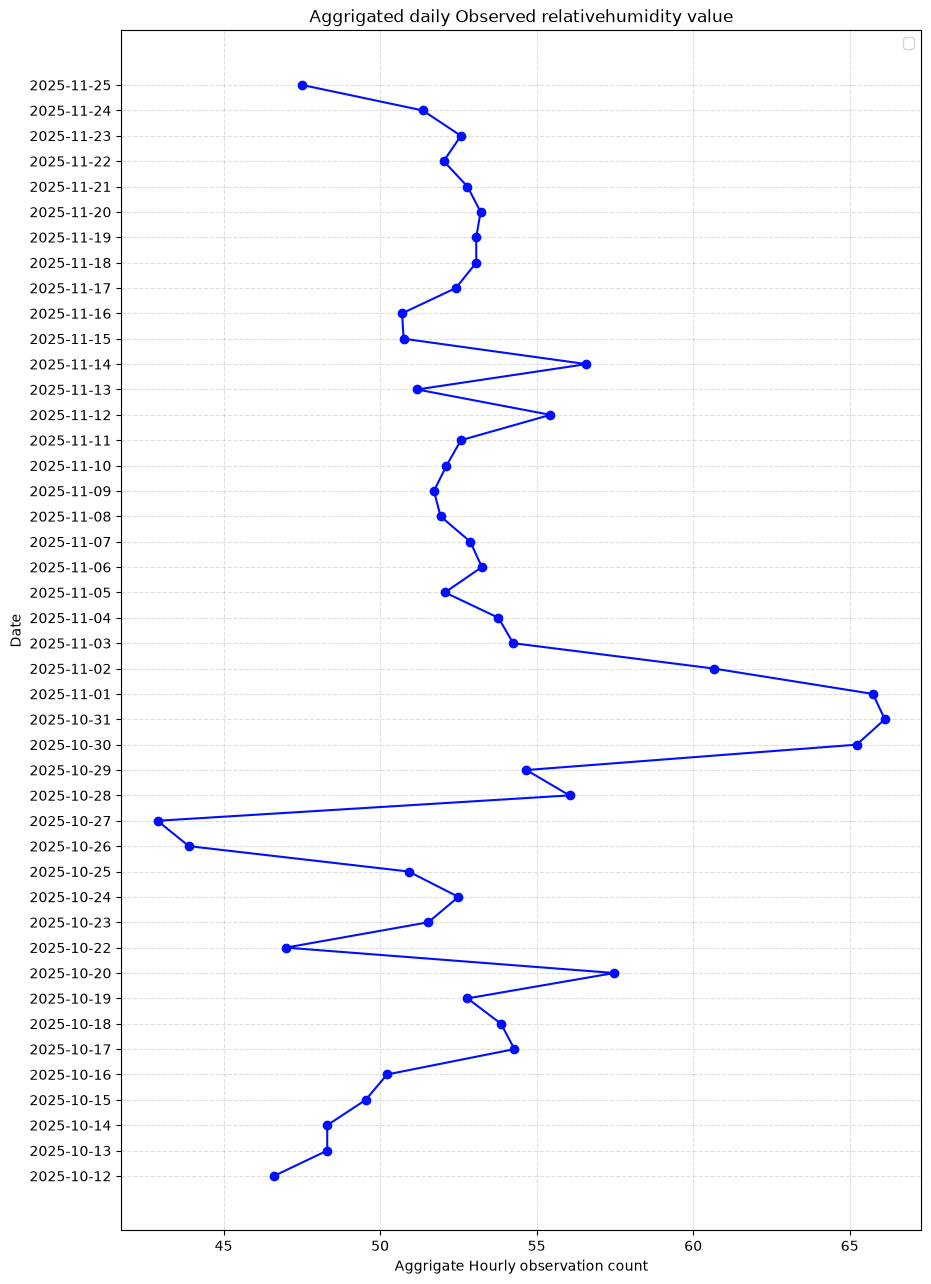

In [7]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [8]:
df30 = pd.read_csv('cleaned_HandigaunLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",relativehumidity,67.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,06:45:00
1,2848864,"Dabali, Handigaun",relativehumidity,64.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,07:45:00
2,2848864,"Dabali, Handigaun",relativehumidity,53.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,08:45:00
3,2848864,"Dabali, Handigaun",relativehumidity,43.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,09:45:00
4,2848864,"Dabali, Handigaun",relativehumidity,39.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
621,2848864,"Dabali, Handigaun",relativehumidity,66.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,01:45:00
622,2848864,"Dabali, Handigaun",relativehumidity,66.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,02:45:00
623,2848864,"Dabali, Handigaun",relativehumidity,67.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,03:45:00
624,2848864,"Dabali, Handigaun",relativehumidity,67.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,04:45:00


In [9]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-12
1      2026-09-12
2      2026-09-12
3      2026-09-12
4      2026-09-12
          ...    
621    2026-10-12
622    2026-10-12
623    2026-10-12
624    2026-10-12
625    2026-10-12
Name: date, Length: 626, dtype: str>

In [10]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [11]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,52.94,18
1,2026-09-13,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,55.83,24
2,2026-09-14,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,57.67,24
3,2026-09-15,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,56.38,24
4,2026-09-16,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,56.67,24
5,2026-09-17,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,62.89,9
6,2026-09-20,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,67.50,6
7,2026-09-21,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,57.21,24
8,2026-09-22,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,58.38,24
9,2026-09-23,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,62.00,24


/tmp/ipykernel_35292/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


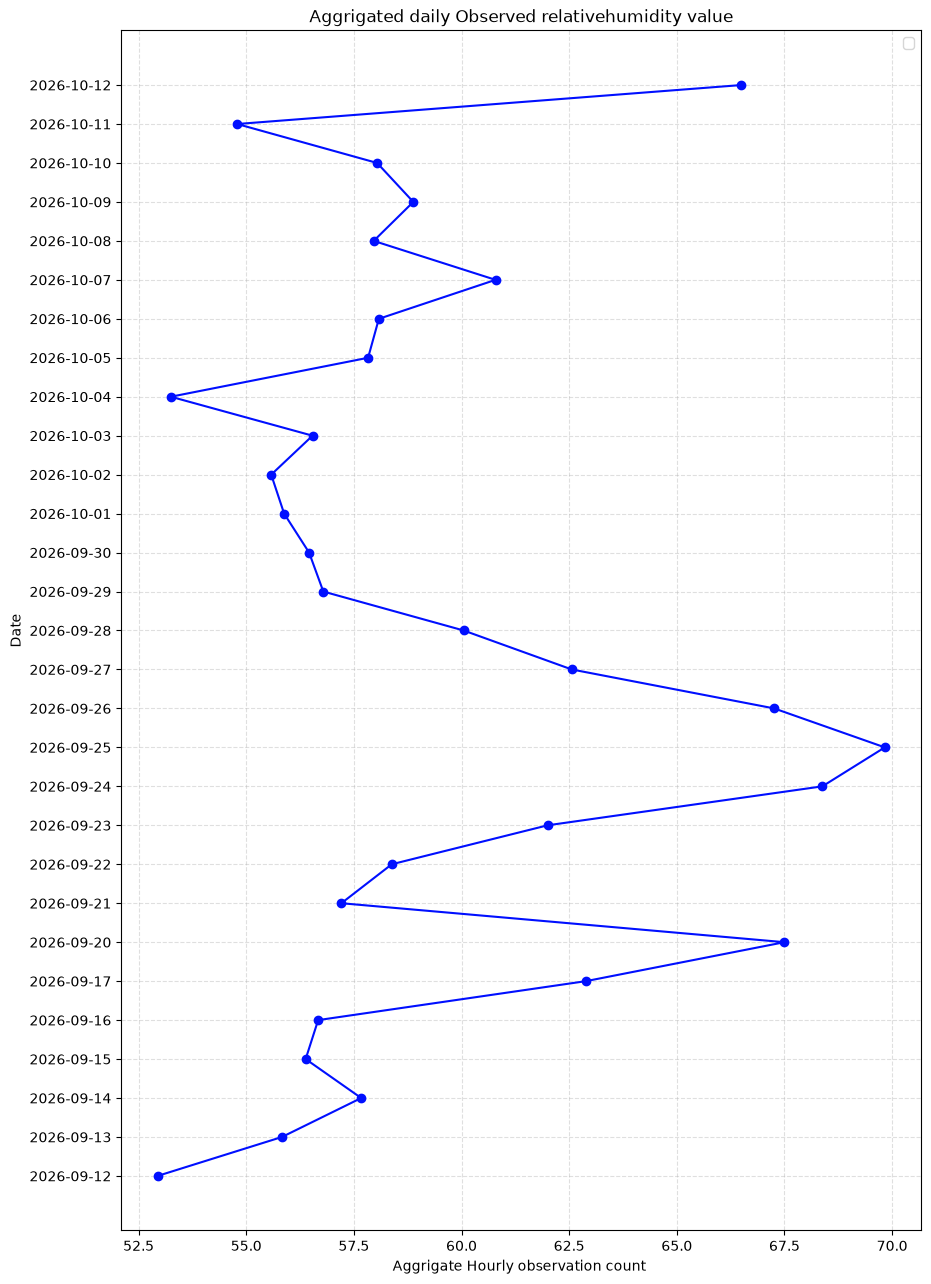

In [12]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [13]:
df7 = pd.read_csv('cleaned_HandigaunLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",relativehumidity,64.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,06:45:00
1,2848864,"Dabali, Handigaun",relativehumidity,61.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,07:45:00
2,2848864,"Dabali, Handigaun",relativehumidity,54.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,08:45:00
3,2848864,"Dabali, Handigaun",relativehumidity,45.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,09:45:00
4,2848864,"Dabali, Handigaun",relativehumidity,37.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,2848864,"Dabali, Handigaun",relativehumidity,66.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,01:45:00
164,2848864,"Dabali, Handigaun",relativehumidity,66.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,02:45:00
165,2848864,"Dabali, Handigaun",relativehumidity,67.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,03:45:00
166,2848864,"Dabali, Handigaun",relativehumidity,67.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-12,04:45:00


In [14]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

In [15]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [16]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,56.28,18
1,2026-10-06,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,58.08,24
2,2026-10-07,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,60.79,24
3,2026-10-08,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,57.96,24
4,2026-10-09,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,58.88,24
5,2026-10-10,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,58.04,24
6,2026-10-11,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,54.79,24
7,2026-10-12,2848864,"Dabali, Handigaun",relativehumidity,%,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,66.50,6


/tmp/ipykernel_35292/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


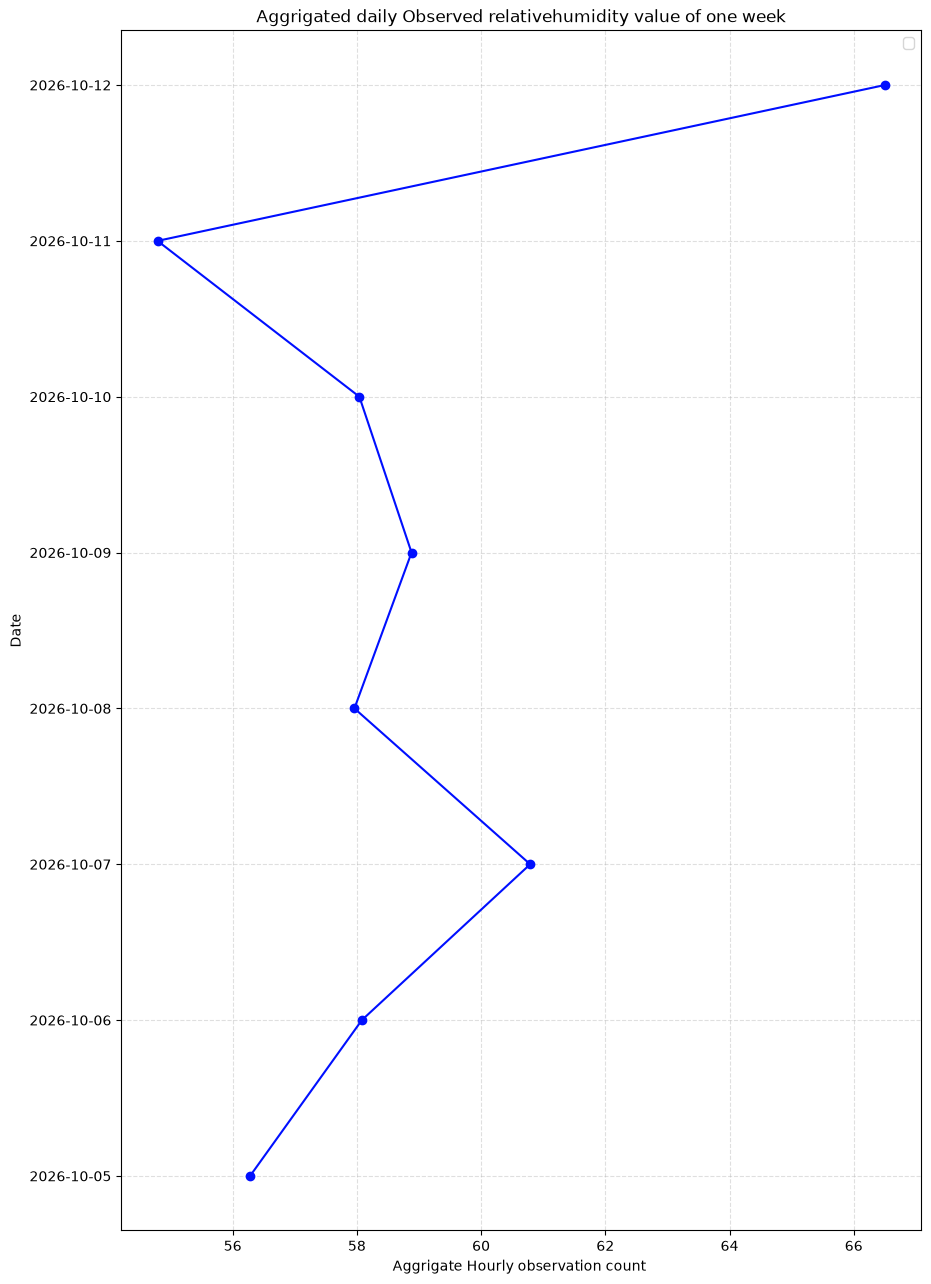

In [17]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [18]:
df24 = pd.read_csv('cleaned_HandigaunLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,2848864,"Dabali, Handigaun",relativehumidity,66.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,06:45:00
1,2848864,"Dabali, Handigaun",relativehumidity,61.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,07:45:00
2,2848864,"Dabali, Handigaun",relativehumidity,54.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,08:45:00
3,2848864,"Dabali, Handigaun",relativehumidity,44.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,09:45:00
4,2848864,"Dabali, Handigaun",relativehumidity,38.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,10:45:00
5,2848864,"Dabali, Handigaun",relativehumidity,36.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,11:45:00
6,2848864,"Dabali, Handigaun",relativehumidity,37.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,12:45:00
7,2848864,"Dabali, Handigaun",relativehumidity,38.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,13:45:00
8,2848864,"Dabali, Handigaun",relativehumidity,39.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,14:45:00
9,2848864,"Dabali, Handigaun",relativehumidity,40.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.681891,85.287078,Unknown Person,AirGradient,2026-10-11,15:45:00


In [19]:
df24['time'].unique()

<ArrowStringArray>
['06:45:00', '07:45:00', '08:45:00', '09:45:00', '10:45:00', '11:45:00',
 '12:45:00', '13:45:00', '14:45:00', '15:45:00', '16:45:00', '17:45:00',
 '18:45:00', '19:45:00', '20:45:00', '21:45:00', '22:45:00', '23:45:00',
 '00:45:00', '01:45:00', '02:45:00', '03:45:00', '04:45:00', '05:45:00']
Length: 24, dtype: str

In [20]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_35292/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


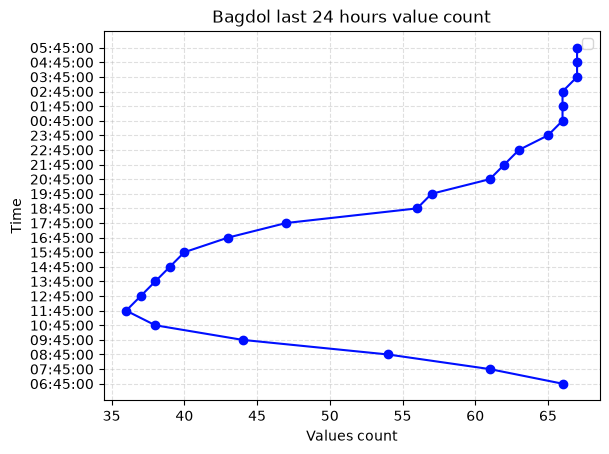

In [21]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()